# 06 - Paper-ready tables, figures and a results draft
Collects everything produced by notebooks 01-05 and turns it into files you can drop into a manuscript. Needs only numpy and matplotlib.

**Tables** (CSV + Markdown + LaTeX with `booktabs`, best value in bold) - dataset cleaning and split, main results with 95% intervals, paired comparisons against the baseline, external validation and unseen-disease detection, implementation details.
**Figures** (vector PDF + 300 dpi PNG, colour-blind-safe palette, single/double-column widths) - architecture, dataset, results (referral, calibration, training), confusion matrices, external validation. Grad-CAM and error figures are copied over from notebook 04.
**Text** - `draft_results.md`: factual sentences generated from your own numbers (including honest "no clear difference" wording when that is what the data say), plus a limitations list and a pre-submission checklist.
**Reproducibility** - `reproducibility.json` with versions, seeds, settings and dataset statistics.

Everything is written to `paper/`. Sections whose inputs are missing (for example no external validation yet) are skipped with a note, so you can run this at any stage and re-run it later.

## 1. Settings, style and helpers

In [1]:
import re, csv, json, math, platform, shutil, collections
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# ---------------- settings ----------------
OUT_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT_clean")     # clean dataset (notebook 01)
RUNS_DIR = Path("outputs") / "runs"                                    # notebook 03
CMP_DIR = Path("outputs") / "comparison"                               # notebook 04
EXT_DIR = Path("outputs") / "external"                                 # notebook 05
PAPER_DIR = Path("paper")
BASELINE = "cnn_softmax"
MAIN = None                      # the variant you present as "ours", e.g. "ms_evidential"; None = best macro-F1
DPI = 300
# -------------------------------------------

FIG_DIR, TAB_DIR = PAPER_DIR / "figures", PAPER_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

LABEL = {"cnn_softmax": "CNN + softmax (baseline)", "cnn_evidential": "CNN + evidential",
         "ms_softmax": "Multi-scale transformer + softmax", "ms_evidential": "MS-OCTFormer (full)"}
COLOR = {"cnn_softmax": "#555555", "cnn_evidential": "#E69F00", "ms_softmax": "#0072B2", "ms_evidential": "#D55E00"}   # Okabe-Ito
ORDER = list(LABEL)
CM_W1, CM_W2 = 3.5, 7.2          # single / double column width in inches

plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "legend.fontsize": 7, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "figure.dpi": 110, "savefig.bbox": "tight", "pdf.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def read_csv(path):
    with open(path, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

def read_json(path):
    return json.load(open(path, encoding="utf-8")) if Path(path).exists() else None

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=DPI)
    plt.show()
    plt.close(fig)
    print(f"  saved figures/{name}.pdf and .png")

def tex_escape(s):
    s = str(s)
    for a, b in (("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#"), ("±", r"$\pm$"), ("Δ", r"$\Delta$")):
        s = s.replace(a, b)
    return s

def write_table(name, headers, rows, caption, label, directions=None):
    # a cell is a string, or (string, number) so the best value in a column can be set in bold
    ncol = len(headers)
    directions = directions or [None] * ncol
    txt = [[c[0] if isinstance(c, tuple) else str(c) for c in r] for r in rows]
    bold = [[False] * ncol for _ in rows]
    for j, d in enumerate(directions):
        if d is None:
            continue
        vals = [(i, r[j][1]) for i, r in enumerate(rows) if isinstance(r[j], tuple) and r[j][1] is not None]
        if len(vals) >= 2:
            target = max(v for _, v in vals) if d == "max" else min(v for _, v in vals)
            for i, v in vals:
                bold[i][j] = abs(v - target) < 1e-12
    with open(TAB_DIR / f"{name}.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f); w.writerow(headers); w.writerows(txt)
    md_rows = [[("**" + t + "**") if bold[i][j] else t for j, t in enumerate(r)] for i, r in enumerate(txt)]
    md_lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * ncol] + ["| " + " | ".join(r) + " |" for r in md_rows]
    (TAB_DIR / f"{name}.md").write_text("\n".join(md_lines), encoding="utf-8")
    tex = [r"\begin{table}[t]", r"\centering", r"\small", rf"\caption{{{tex_escape(caption)}}}", rf"\label{{{label}}}",
           r"\begin{tabular}{l" + "c" * (ncol - 1) + "}", r"\toprule", " & ".join(tex_escape(h) for h in headers) + r" \\", r"\midrule"]
    for i, r in enumerate(txt):
        tex.append(" & ".join((r"\textbf{" + tex_escape(t) + "}") if bold[i][j] else tex_escape(t) for j, t in enumerate(r)) + r" \\")
    tex += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    (TAB_DIR / f"{name}.tex").write_text("\n".join(tex), encoding="utf-8")
    print("\n".join(md_lines))
    print(f"  saved tables/{name}.csv, .md, .tex\n")

def mean_std(vals):
    vals = [v for v in vals if v is not None]
    if not vals:
        return None, None
    return float(np.mean(vals)), (float(np.std(vals)) if len(vals) > 1 else None)

def verdict(ci):
    if ci is None or any(c is None or (isinstance(c, float) and math.isnan(c)) for c in ci):
        return "n/a"
    return "better" if ci[0] > 0 else ("worse" if ci[1] < 0 else "no clear difference")

## 2. Load everything that exists

In [2]:
runs = {}
for d in sorted(RUNS_DIR.glob("*_s*")):
    m = re.match(r"^(cnn|ms)_(softmax|evidential)_s(\d+)$", d.name)
    if m and (d / "metrics.json").exists() and (d / "test_outputs.npz").exists():
        o = np.load(d / "test_outputs.npz")
        runs[d.name] = dict(dir=d, variant=f"{m[1]}_{m[2]}", seed=int(m[3]), metrics=read_json(d / "metrics.json"),
                            config=read_json(d / "config.json") or {}, history=read_json(d / "history.json"),
                            y=o["y"], pred=o["pred"], unc=o["unc"], probs=o["probs"])
if not runs:
    raise FileNotFoundError(f"No finished runs in {RUNS_DIR}. Run notebook 03 first.")
VARIANTS = [v for v in ORDER if any(r["variant"] == v for r in runs.values())]
first = {v: min((r for r in runs.values() if r["variant"] == v), key=lambda r: r["seed"]) for v in VARIANTS}
n_seeds = {v: sum(r["variant"] == v for r in runs.values()) for v in VARIANTS}
CLASSES = list(next(iter(runs.values()))["metrics"]["test"]["per_class"])
K = len(CLASSES)
N_TEST = len(next(iter(runs.values()))["y"])
f1_of = lambda v: np.mean([r["metrics"]["test"]["macro_f1"] for r in runs.values() if r["variant"] == v])
BEST = max(VARIANTS, key=f1_of)
MAIN_V = MAIN if MAIN in VARIANTS else BEST

MANIFEST = read_csv(OUT_ROOT / "manifest.csv") if (OUT_ROOT / "manifest.csv").exists() else None
DROPPED = read_csv(OUT_ROOT / "dropped.csv") if (OUT_ROOT / "dropped.csv").exists() else None
DS_STATS = read_json(OUT_ROOT / "stats.json")
PIPE = read_json(OUT_ROOT / "pipeline.json") or {}
PAIRED = read_json(CMP_DIR / "paired_tests.json")
EXT = read_json(EXT_DIR / "external_results.json")

have = lambda x: "found" if x else "MISSING"
print(f"Runs: {', '.join(runs)}")
print(f"Variants: {', '.join(VARIANTS)} | seeds per variant: {n_seeds} | test scans: {N_TEST:,} | main variant: {MAIN_V}")
print(f"Dataset manifest: {have(MANIFEST)} | dropped list: {have(DROPPED)} | pipeline.json: {have(PIPE)} | "
      f"paired tests: {have(PAIRED)} | external results: {have(EXT)}")

Runs: cnn_softmax_s42
Variants: cnn_softmax | seeds per variant: {'cnn_softmax': 1} | test scans: 7,734 | main variant: cnn_softmax
Dataset manifest: found | dropped list: found | pipeline.json: found | paired tests: MISSING | external results: found


## 3. Tables

In [3]:
# ---- Table 1: dataset cleaning and split -------------------------------------------------------
FUNNEL = {}
if MANIFEST and DROPPED:
    raw_total = len(MANIFEST) + len(DROPPED)
    reasons = collections.Counter(r["reason"].split(":")[0] for r in DROPPED)
    FUNNEL = dict(raw_total=raw_total, kept=len(MANIFEST), reasons=dict(reasons))
    rows = [["Raw files in the public collection", (f"{raw_total:,}", None), "100.0"]]
    for reason, n in reasons.most_common():
        rows.append([f"Removed: {reason}", f"-{n:,}", f"{n / raw_total * 100:.1f}"])
    rows.append(["Clean dataset", f"{len(MANIFEST):,}", f"{len(MANIFEST) / raw_total * 100:.1f}"])
    write_table("table1a_cleaning", ["Step", "Scans", "% of raw"], rows,
                "Data cleaning. Every removed file is listed with its reason in dropped.csv.", "tab:cleaning")

    classes_ds = sorted({r["cls"] for r in MANIFEST})
    rows = []
    for s in ("train", "val", "test"):
        rs = [r for r in MANIFEST if r["split"] == s]
        rows.append([s.capitalize()] + [f"{sum(r['cls'] == c for r in rs):,}" for c in classes_ds] +
                    [f"{len(rs):,}", f"{len({r['patient'] for r in rs}):,}"])
    write_table("table1b_split", ["Split"] + classes_ds + ["Scans", "Patients"], rows,
                "Patient-disjoint split of the clean dataset. Patients that share an image or have near-identical scans are kept in the same split.",
                "tab:split")
else:
    print("Table 1 skipped: manifest.csv / dropped.csv not found in", OUT_ROOT)

# ---- Table 2: main results ---------------------------------------------------------------------
rows = []
for v in VARIANTS:
    rs = [r for r in runs.values() if r["variant"] == v]
    t = lambda k: mean_std([r["metrics"]["test"].get(k) for r in rs])
    acc, f1, ece, au, a90 = t("acc"), t("macro_f1"), t("ece"), t("auroc"), t("acc_at_90")
    if len(rs) == 1:
        tt = rs[0]["metrics"]["test"]
        acc_s = f"{acc[0] * 100:.2f} [{tt['acc_ci95'][0] * 100:.2f}, {tt['acc_ci95'][1] * 100:.2f}]"
        f1_s = f"{f1[0]:.4f} [{tt['f1_ci95'][0]:.4f}, {tt['f1_ci95'][1]:.4f}]"
    else:
        acc_s, f1_s = f"{acc[0] * 100:.2f} ± {acc[1] * 100:.2f}", f"{f1[0]:.4f} ± {f1[1]:.4f}"
    ft = lambda p, nd, sc=1.0: ("n/a" if p[0] is None else f"{p[0] * sc:.{nd}f}" + (f" ± {p[1] * sc:.{nd}f}" if p[1] is not None else ""), p[0])
    rows.append([LABEL[v], (acc_s, acc[0]), (f1_s, f1[0]), ft(ece, 4), ft(au, 3), ft(a90, 2, 100.0),
                 f"{rs[0]['metrics']['cfg'].get('params_m', float('nan')):.1f}", str(len(rs))])
write_table("table2_main_results", ["Model", "Accuracy (%)", "Macro-F1", "ECE", "AUROC (error det.)", "Acc. at 90% coverage (%)", "Params (M)", "Seeds"],
            rows, f"Test-set results on {N_TEST:,} patient-disjoint scans. Brackets: 95% bootstrap interval over test scans; "
                  "'±' is the standard deviation over seeds. Bold = best.", "tab:main",
            directions=[None, "max", "max", "min", "max", "max", None, None])

# ---- Table 3: paired comparison with the baseline ---------------------------------------------------
if PAIRED and BASELINE in VARIANTS:
    rows = []
    for v in VARIANTS:
        c = PAIRED.get(v)
        if not c:
            continue
        rows.append([LABEL[v], f"{c['d_acc_pp']:+.2f} [{c['acc'][0] * 100:+.2f}, {c['acc'][1] * 100:+.2f}]", f"{c['mcnemar_p']:.3g}",
                     f"[{c['f1'][0]:+.4f}, {c['f1'][1]:+.4f}]", f"[{c['auroc'][0]:+.3f}, {c['auroc'][1]:+.3f}]",
                     f"{verdict(c['f1'])} (F1) / {verdict(c['auroc'])} (AUROC)"])
    write_table("table3_paired", ["Variant vs. baseline", "Δ accuracy (pp) [95% CI]", "McNemar p", "Δ macro-F1 [95% CI]", "Δ AUROC [95% CI]", "Verdict"],
                rows, f"Paired comparison with {LABEL[BASELINE]} on identical test scans. An interval that contains 0 means no clear difference.", "tab:paired")
else:
    print("Table 3 skipped: run notebook 04 (paired tests) with a baseline run first.")

# ---- Table 4: external validation ----------------------------------------------------------------
if EXT:
    idr, odr = EXT["id_results"], EXT.get("ood_results") or {}
    rows = []
    for name, r in idr.items():
        v = re.sub(r"_s\d+$", "", name)
        rows.append([LABEL.get(v, name), (f"{r['acc'] * 100:.2f} [{r['acc_ci'][0] * 100:.2f}, {r['acc_ci'][1] * 100:.2f}]", r["acc"]),
                     f"{r['internal_acc'] * 100:.2f}", f"{(r['acc'] - r['internal_acc']) * 100:+.2f}", (f"{r['macro_f1']:.4f}", r["macro_f1"]),
                     f"{r['ece']:.4f}", "n/a" if r["auroc"] is None else f"{r['auroc']:.3f}"])
    write_table("table4a_external", ["Model", "External accuracy (%)", "Internal (%)", "Change (pp)", "External macro-F1", "ECE", "AUROC (error det.)"], rows,
                f"External validation on {EXT['in_distribution']:,} scans of the four known classes ({EXT['overlap_removed']:,} scans overlapping with the "
                "training data were removed before evaluation).", "tab:external", directions=[None, "max", None, None, "max", None, None])
    if odr:
        rows = []
        for name, r in odr.items():
            v = re.sub(r"_s\d+$", "", name)
            rows.append([LABEL.get(v, name), (f"{r['native']['auroc']:.3f}", r["native"]["auroc"]), (f"{r['1-maxprob']['auroc']:.3f}", r["1-maxprob"]["auroc"]),
                         (f"{r['entropy']['auroc']:.3f}", r["entropy"]["auroc"]), f"{r['native']['fpr95']:.3f}"])
        write_table("table4b_unseen", ["Model", "AUROC: own score", "AUROC: 1 - max prob.", "AUROC: entropy", "FPR at 95% TPR (own score)"], rows,
                    f"Detecting {EXT['unseen']:,} scans of diseases outside the label set against {EXT['in_distribution']:,} known-class scans from the same "
                    "external dataset. 0.5 = chance.", "tab:unseen", directions=[None, "max", "max", "max", None])
else:
    print("Table 4 skipped: external validation (notebook 05) not run yet.")

# ---- Table 5: implementation details ----------------------------------------------------------------
cfg = first[MAIN_V]["config"] or first[MAIN_V]["metrics"].get("cfg", {})
aug = PIPE.get("augmentation", {})
g = lambda k, d="n/a": cfg.get(k, d)
rows = [["Backbone", "ConvNeXt-Tiny, ImageNet-pretrained"], ["Input size", f"{PIPE.get('net_input_size', g('img_size'))} x {PIPE.get('net_input_size', g('img_size'))}"],
        ["Optimiser", "AdamW"], ["Learning rate (backbone / head)", f"{g('lr_backbone')} / {g('lr_head')}"], ["Weight decay", str(g("weight_decay"))],
        ["Schedule", f"{g('warmup_epochs')} warm-up epoch(s), cosine decay"], ["Epochs x samples per epoch", f"{g('epochs')} x {g('samples_per_epoch')}"],
        ["Batch size", str(g("batch_size"))], ["Sampling", str(g("sampler"))], ["Weight averaging (EMA)", f"{g('ema')} (decay {g('ema_decay')})"],
        ["Label smoothing", str(g("label_smoothing"))], ["Gradient clipping", str(g("grad_clip"))],
        ["Evidential loss KL weight / anneal epochs", f"{g('kl_weight')} / {g('kl_anneal_epochs')}"],
        ["Transformer (multi-scale variants)", f"{g('depth')} layers, {g('heads')} heads, width {g('dim')}"],
        ["Normalisation", f"{PIPE.get('norm', 'n/a')}"], ["Augmentation (train)", ", ".join(f"{k}={v}" for k, v in aug.items()) or "n/a"],
        ["Stored image size / resize", f"{(DS_STATS or {}).get('image_size', 'n/a')} px / {(DS_STATS or {}).get('resize_mode', 'n/a')}"],
        ["Mixed precision", "yes (float16 autocast)"], ["Model selection", "best validation macro-F1; test set scored once"]]
write_table("table5_implementation", ["Setting", "Value"], rows, f"Training and preprocessing settings (run {first[MAIN_V]['dir'].name}).", "tab:impl")

| Step | Scans | % of raw |
|---|---|---|
| Raw files in the public collection | 84,484 | 100.0 |
| Removed: exact duplicate (one copy kept) | -7,341 | 8.7 |
| Removed: same image under different class folders | -466 | 0.6 |
| Clean dataset | 76,677 | 90.8 |
  saved tables/table1a_cleaning.csv, .md, .tex

| Split | CNV | DME | DRUSEN | NORMAL | Scans | Patients |
|---|---|---|---|---|---|---|
| Train | 25,037 | 8,845 | 6,179 | 21,093 | 61,154 | 3,714 |
| Val | 3,136 | 1,081 | 878 | 2,694 | 7,789 | 502 |
| Test | 3,267 | 1,191 | 776 | 2,500 | 7,734 | 440 |
  saved tables/table1b_split.csv, .md, .tex

| Model | Accuracy (%) | Macro-F1 | ECE | AUROC (error det.) | Acc. at 90% coverage (%) | Params (M) | Seeds |
|---|---|---|---|---|---|---|---|
| CNN + softmax (baseline) | 93.69 [93.17, 94.19] | 0.9207 [0.9140, 0.9273] | 0.0511 | 0.831 | 96.98 | 27.8 | 1 |
  saved tables/table2_main_results.csv, .md, .tex

Table 3 skipped: run notebook 04 (paired tests) with a baseline run first.
| Model 

## 4. Figures
All figures are saved as vector PDF and 300 dpi PNG in `paper/figures/`. Single-column figures are 3.5 in wide, double-column 7.2 in.

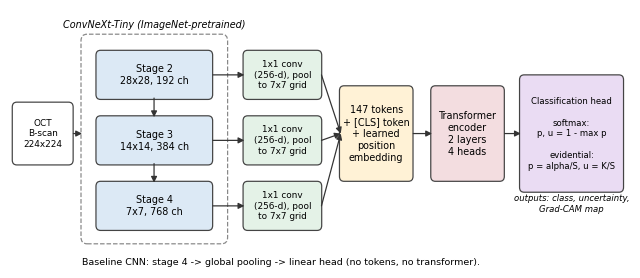

  saved figures/fig1_architecture.pdf and .png


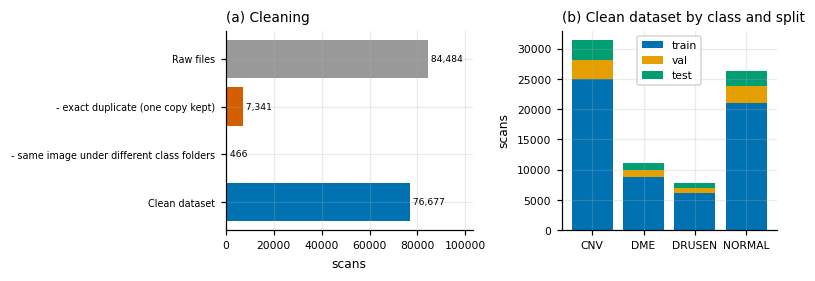

  saved figures/fig2_dataset.pdf and .png


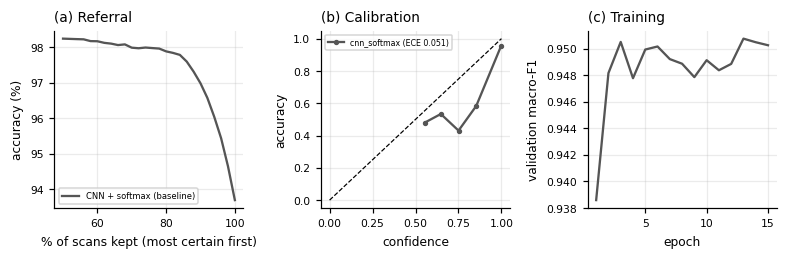

  saved figures/fig3_results.pdf and .png


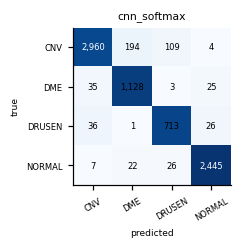

  saved figures/fig4_confusion.pdf and .png


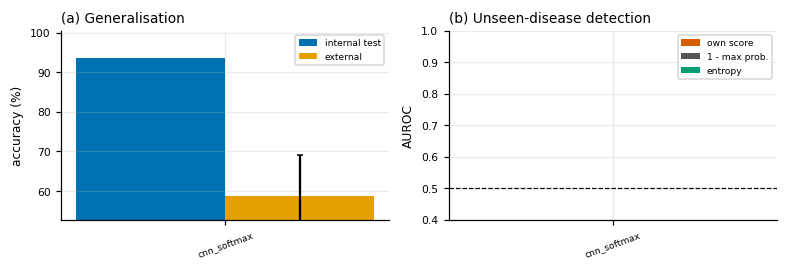

  saved figures/fig5_external.pdf and .png
  copied gradcam.png from notebook 04
  copied confident_mistakes.png from notebook 04


In [4]:
# ---- Fig 1: architecture ----------------------------------------------------------------------------
def box(ax, x, y, w, h, text, fc="#F2F2F2", ec="#444444", fs=6.3, lw=0.8, bold=False, ls="-"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.25,rounding_size=0.9", fc=fc, ec=ec, lw=lw, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", linespacing=1.25)

def arrow(ax, p0, p1, style="-|>"):
    ax.annotate("", xy=p1, xytext=p0, arrowprops=dict(arrowstyle=style, lw=0.8, color="#333333", shrinkA=0, shrinkB=0))

fig, ax = plt.subplots(figsize=(CM_W2, 2.9))
ax.set_xlim(0, 121); ax.set_ylim(0, 45); ax.axis("off"); ax.grid(False)
box(ax, 0.5, 17, 11.5, 11, "OCT\nB-scan\n224x224", fc="#FFFFFF", fs=5.8)
ax.add_patch(FancyBboxPatch((14, 2.5), 28.5, 38, boxstyle="round,pad=0.2,rounding_size=1.2", fc="none", ec="#888888", lw=0.8, ls="--"))
ax.text(28.2, 41.8, "ConvNeXt-Tiny (ImageNet-pretrained)", ha="center", fontsize=6.3, style="italic")
stage_y = (29, 17, 5)
for y0, txt in zip(stage_y, ("Stage 2\n28x28, 192 ch", "Stage 3\n14x14, 384 ch", "Stage 4\n7x7, 768 ch")):
    box(ax, 17, y0, 22.5, 8.5, txt, fc="#DCE9F5")
arrow(ax, (28.2, stage_y[0]), (28.2, stage_y[1] + 8.5)); arrow(ax, (28.2, stage_y[1]), (28.2, stage_y[2] + 8.5))
arrow(ax, (12.3, 22.5), (14, 22.5))
for y0 in stage_y:
    box(ax, 46, y0, 15, 8.5, "1x1 conv\n(256-d), pool\nto 7x7 grid", fc="#E4F2E7", fs=5.8)
    arrow(ax, (39.8, y0 + 4.25), (46, y0 + 4.25))
box(ax, 65, 14, 14, 17, "147 tokens\n+ [CLS] token\n+ learned\nposition\nembedding", fc="#FFF2D6")
for y0 in stage_y:
    arrow(ax, (61.2, y0 + 4.25), (65, 22.5))
box(ax, 83, 14, 14, 17, "Transformer\nencoder\n2 layers\n4 heads", fc="#F3DDE0")
arrow(ax, (79.3, 22.5), (83, 22.5))
box(ax, 100.5, 12, 20, 21, "Classification head\n\nsoftmax:\np, u = 1 - max p\n\nevidential:\np = alpha/S, u = K/S", fc="#EADCF3", fs=5.6)
arrow(ax, (97.3, 22.5), (100.5, 22.5))
ax.text(110.5, 8.2, "outputs: class, uncertainty,\nGrad-CAM map", ha="center", fontsize=5.6, style="italic")
ax.text(14, -0.3, "Baseline CNN: stage 4 -> global pooling -> linear head (no tokens, no transformer).", fontsize=6.2, va="top")
save_fig(fig, "fig1_architecture")

# ---- Fig 2: dataset -------------------------------------------------------------------------------------
if FUNNEL:
    fig, axs = plt.subplots(1, 2, figsize=(CM_W2, 2.6), gridspec_kw={"width_ratios": [1.15, 1]})
    items = [("Raw files", FUNNEL["raw_total"])] + [(f"- {k}", n) for k, n in sorted(FUNNEL["reasons"].items(), key=lambda kv: -kv[1])] + [("Clean dataset", FUNNEL["kept"])]
    cols = ["#999999"] + ["#D55E00"] * (len(items) - 2) + ["#0072B2"]
    axs[0].barh(range(len(items)), [n for _, n in items], color=cols)
    axs[0].set_yticks(range(len(items))); axs[0].set_yticklabels([k for k, _ in items], fontsize=6.3); axs[0].invert_yaxis()
    for i, (_, n) in enumerate(items):
        axs[0].text(n, i, f" {n:,}", va="center", fontsize=6)
    axs[0].set_xlim(0, FUNNEL["raw_total"] * 1.22); axs[0].set_xlabel("scans"); axs[0].set_title("(a) Cleaning", loc="left")
    cls_ds = sorted({r["cls"] for r in MANIFEST})
    bottom = np.zeros(len(cls_ds))
    for s, c in zip(("train", "val", "test"), ("#0072B2", "#E69F00", "#009E73")):
        cnt = np.array([sum(1 for r in MANIFEST if r["split"] == s and r["cls"] == k) for k in cls_ds])
        axs[1].bar(cls_ds, cnt, bottom=bottom, color=c, label=s); bottom += cnt
    axs[1].set_ylabel("scans"); axs[1].set_title("(b) Clean dataset by class and split", loc="left"); axs[1].legend()
    plt.tight_layout(); save_fig(fig, "fig2_dataset")

# ---- Fig 3: referral, calibration, training --------------------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(CM_W2, 2.4))
cov = np.linspace(0.5, 1.0, 26)
def acc_at_cov(y, pred, unc, c):
    keep_ = np.argsort(unc, kind="stable")[:max(1, int(round(c * len(y))))]
    return float((y[keep_] == pred[keep_]).mean()) * 100
for v in VARIANTS:
    r = first[v]
    axs[0].plot(cov * 100, [acc_at_cov(r["y"], r["pred"], r["unc"], c) for c in cov], color=COLOR[v], label=LABEL[v])
axs[0].set_xlabel("% of scans kept (most certain first)"); axs[0].set_ylabel("accuracy (%)"); axs[0].set_title("(a) Referral", loc="left")
axs[0].legend(fontsize=5.5, loc="best")

axs[1].plot([0, 1], [0, 1], "k--", lw=0.8)
for v in VARIANTS:
    r = first[v]
    conf, cor = r["probs"].max(1), (r["pred"] == r["y"]).astype(float)
    edges = np.linspace(0, 1, 11)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 10:
            xs.append(conf[m].mean()); ys.append(cor[m].mean())
    axs[1].plot(xs, ys, "o-", ms=2.5, color=COLOR[v], label=f"{v} (ECE {r['metrics']['test']['ece']:.3f})")
axs[1].set_xlabel("confidence"); axs[1].set_ylabel("accuracy"); axs[1].set_title("(b) Calibration", loc="left"); axs[1].legend(fontsize=5.2)

for v in VARIANTS:
    h = first[v]["history"]
    if h:
        axs[2].plot(range(1, len(h["val_f1"]) + 1), h["val_f1"], color=COLOR[v], label=v)
axs[2].set_xlabel("epoch"); axs[2].set_ylabel("validation macro-F1"); axs[2].set_title("(c) Training", loc="left")
plt.tight_layout(); save_fig(fig, "fig3_results")

# ---- Fig 4: confusion matrices ------------------------------------------------------------------------------
fig, axs = plt.subplots(1, len(VARIANTS), figsize=(CM_W2, 2.3), squeeze=False)
for ax, v in zip(axs[0], VARIANTS):
    cm = np.array(first[v]["metrics"]["test"]["confusion_matrix"])
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=5.5, color="white" if cm[i, j] > cm.max() * 0.5 else "black")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, fontsize=5.5, rotation=30); ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES, fontsize=5.5)
    ax.set_title(v, fontsize=7); ax.set_xlabel("predicted", fontsize=6)
axs[0, 0].set_ylabel("true", fontsize=6)
plt.tight_layout(); save_fig(fig, "fig4_confusion")

# ---- Fig 5: external validation ---------------------------------------------------------------------------------
if EXT:
    idr, odr = EXT["id_results"], EXT.get("ood_results") or {}
    names = list(idr)
    fig, axs = plt.subplots(1, 2 if odr else 1, figsize=(CM_W2 if odr else CM_W1, 2.5), squeeze=False)
    x = np.arange(len(names))
    axs[0, 0].bar(x - 0.2, [idr[n]["internal_acc"] * 100 for n in names], 0.4, label="internal test", color="#0072B2")
    axs[0, 0].bar(x + 0.2, [idr[n]["acc"] * 100 for n in names], 0.4, label="external", color="#E69F00",
                  yerr=[[(idr[n]["acc"] - idr[n]["acc_ci"][0]) * 100 for n in names], [(idr[n]["acc_ci"][1] - idr[n]["acc"]) * 100 for n in names]], capsize=2)
    axs[0, 0].set_xticks(x); axs[0, 0].set_xticklabels([re.sub(r"_s\d+$", "", n) for n in names], rotation=20, fontsize=6)
    axs[0, 0].set_ylim(max(0, min(min(idr[n]["acc"] for n in names), min(idr[n]["internal_acc"] for n in names)) * 100 - 6), 100.5)
    axs[0, 0].set_ylabel("accuracy (%)"); axs[0, 0].set_title("(a) Generalisation", loc="left"); axs[0, 0].legend(fontsize=6)
    if odr:
        wd = 0.26
        for k, (sname, c) in enumerate((("native", "#D55E00"), ("1-maxprob", "#555555"), ("entropy", "#009E73"))):
            axs[0, 1].bar(x + (k - 1) * wd, [odr[n][sname]["auroc"] for n in names], wd, color=c, label={"native": "own score", "1-maxprob": "1 - max prob.", "entropy": "entropy"}[sname])
        axs[0, 1].axhline(0.5, color="k", ls="--", lw=0.8); axs[0, 1].set_ylim(0.4, 1.0)
        axs[0, 1].set_xticks(x); axs[0, 1].set_xticklabels([re.sub(r"_s\d+$", "", n) for n in names], rotation=20, fontsize=6)
        axs[0, 1].set_ylabel("AUROC"); axs[0, 1].set_title("(b) Unseen-disease detection", loc="left"); axs[0, 1].legend(fontsize=6)
    plt.tight_layout(); save_fig(fig, "fig5_external")
else:
    print("Fig 5 skipped: external validation not run yet.")

# ---- Grad-CAM / error figures from notebook 04 -----------------------------------------------------------------
for fname in ("gradcam.png", "confident_mistakes.png"):
    if (CMP_DIR / fname).exists():
        shutil.copy(CMP_DIR / fname, FIG_DIR / fname)
        print("  copied", fname, "from notebook 04")

## 5. Draft of the results section
Sentences are generated from your numbers. **This is a starting point: check every number against the tables and rewrite it in your own words.**
When the data show no clear difference, the draft says so.

In [10]:
L = ["# Results draft", "", "> DRAFT generated from the result files. Verify every number, rewrite in your own words, and do not keep claims the data do not support.", ""]

L += ["## Data"]
if FUNNEL:
    rs = FUNNEL["reasons"]
    rem = ", ".join(f"{n:,} {k.lower()}" for k, n in sorted(rs.items(), key=lambda kv: -kv[1])) or "no files"
    spl = {s: sum(r["split"] == s for r in MANIFEST) for s in ("train", "val", "test")}
    pat = len({r["patient"] for r in MANIFEST})
    L += [f"The public collection contained {FUNNEL['raw_total']:,} scans. After cleaning (removed: {rem}), {FUNNEL['kept']:,} scans from {pat:,} patients remained. "
          f"Patients that shared an image or had near-identical scans were linked into groups, and groups were split into training ({spl['train']:,}), "
          f"validation ({spl['val']:,}) and test ({spl['test']:,}) scans, stratified by class. No patient group and no byte-identical image appears in more than one split.", ""]
else:
    L += ["(dataset files not found - fill in from notebook 01)", ""]

L += ["## Main results"]
for v in VARIANTS:
    t = first[v]["metrics"]["test"]
    L.append(f"- {LABEL[v]}: accuracy {t['acc'] * 100:.2f}% (95% CI {t['acc_ci95'][0] * 100:.2f}-{t['acc_ci95'][1] * 100:.2f}), macro-F1 {t['macro_f1']:.4f}, "
             f"ECE {t['ece']:.4f}, error-detection AUROC {('n/a' if t.get('auroc') is None else format(t['auroc'], '.3f'))}, "
             f"{t['errors']} errors on {N_TEST:,} test scans (seed {first[v]['seed']}).")
L.append("")

L += ["## Comparison with the baseline"]
if PAIRED and BASELINE in VARIANTS:
    for v in VARIANTS:
        c = PAIRED.get(v)
        if not c:
            continue
        va, vf, vu = verdict([c["acc"][0], c["acc"][1]]), verdict(c["f1"]), verdict(c["auroc"])
        L.append(f"- {LABEL[v]} vs. {LABEL[BASELINE]}: accuracy difference {c['d_acc_pp']:+.2f} percentage points (95% CI {c['acc'][0] * 100:+.2f} to {c['acc'][1] * 100:+.2f}; "
                 f"McNemar p = {c['mcnemar_p']:.3g}) - {va}; macro-F1: {vf}; error-detection AUROC: {vu}.")
    L.append("")
    L.append("Wording rule: report 'no clear difference' exactly as such; a simpler model that matches a more complex one is a legitimate finding.")
else:
    L.append("(paired tests not available - run notebook 04)")
L.append("")

L += ["## Uncertainty"]
for v in VARIANTS:
    t = first[v]["metrics"]["test"]
    if t.get("unc_wrong") is not None:
        L.append(f"- {LABEL[v]}: mean uncertainty {t['unc_correct']:.3f} on correct vs {t['unc_wrong']:.3f} on wrong predictions; "
                 f"accuracy on the 90% / 80% most certain scans {t['acc_at_90'] * 100:.2f}% / {t['acc_at_80'] * 100:.2f}%.")
L.append("")

if EXT:
    L += ["## External validation"]
    L.append(f"External scans: {EXT['files']:,} files; {EXT['overlap_removed']:,} ({EXT['overlap_removed'] / max(EXT['files'], 1) * 100:.1f}%) were removed because they overlap with the "
             f"training data (file or image hash); {EXT['in_distribution']:,} known-class and {EXT['unseen']:,} unseen-class scans were evaluated.")
    for name, r in EXT["id_results"].items():
        base = re.sub(r"_s\d+$", "", name)
        L.append(f"- {LABEL.get(base, name)}: external accuracy {r['acc'] * 100:.2f}% (95% CI {r['acc_ci'][0] * 100:.2f}-{r['acc_ci'][1] * 100:.2f}) vs {r['internal_acc'] * 100:.2f}% internal "
                 f"({(r['acc'] - r['internal_acc']) * 100:+.2f} pp), macro-F1 {r['macro_f1']:.4f}.")
    for name, r in (EXT.get("ood_results") or {}).items():
        base = re.sub(r"_s\d+$", "", name)
        L.append(f"- {LABEL.get(base, name)}: unseen-disease detection AUROC {r['native']['auroc']:.3f} (own score), {r['1-maxprob']['auroc']:.3f} (1 - max probability), {r['entropy']['auroc']:.3f} (entropy).")
    L.append("")

L += ["## Limitations (auto-detected, expand as needed)"]
lim = []
if min(n_seeds.values()) < 3:
    lim.append(f"Fewer than 3 seeds for some variants ({n_seeds}); report mean +/- std over >= 3 seeds before claiming differences.")
errs = [first[v]["metrics"]["test"]["errors"] for v in VARIANTS]
if min(errs) < 30:
    lim.append(f"Few test errors ({min(errs)}-{max(errs)}), so intervals around error-based metrics (AUROC) are wide.")
if not EXT:
    lim.append("No external validation yet.")
elif EXT["overlap_removed"] > 0.3 * EXT["files"]:
    lim.append("The external dataset overlaps substantially with the training data; it is only partly independent.")
lim.append("Labels in public OCT collections are not expert-verified for every scan; some label noise is expected (see dropped.csv for conflicts that were removed).")
lim.append("Grad-CAM maps are saliency maps, not validated lesion segmentations.")
L += [f"- {x}" for x in lim] + [""]
(PAPER_DIR / "draft_results.md").write_text("\n".join(L), encoding="utf-8")
print("\n".join(L))
print("\nSaved paper/draft_results.md")

# Results draft

> DRAFT generated from the result files. Verify every number, rewrite in your own words, and do not keep claims the data do not support.

## Data
The public collection contained 84,484 scans. After cleaning (removed: 7,341 exact duplicate (one copy kept), 466 same image under different class folders), 76,677 scans from 4,656 patients remained. Patients that shared an image or had near-identical scans were linked into groups, and groups were split into training (61,154), validation (7,789) and test (7,734) scans, stratified by class. No patient group and no byte-identical image appears in more than one split.

## Main results
- CNN + softmax (baseline): accuracy 93.69% (95% CI 93.17-94.19), macro-F1 0.9207, ECE 0.0511, error-detection AUROC 0.831, 488 errors on 7,734 test scans (seed 42).

## Comparison with the baseline
(paired tests not available - run notebook 04)

## Uncertainty
- CNN + softmax (baseline): mean uncertainty 0.007 on correct vs 0.087 on wrong predicti

## 6. Reproducibility record and pre-submission checklist

In [11]:
env = dict(python=platform.python_version(), platform=platform.platform(), numpy=np.__version__)
try:
    import torch, torchvision
    env.update(torch=torch.__version__, torchvision=torchvision.__version__, cuda=torch.version.cuda,
               gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
except Exception:
    env.update(torch=PIPE.get("torch"), torchvision=PIPE.get("torchvision"))
repro = dict(environment=env, dataset=DS_STATS, pipeline=PIPE, runs={n: dict(seed=r["seed"], config=r["config"], best_epoch=r["metrics"].get("best_epoch"),
             train_minutes=r["metrics"].get("train_minutes")) for n, r in runs.items()}, baseline=BASELINE, main_variant=MAIN_V)
json.dump(repro, open(PAPER_DIR / "reproducibility.json", "w", encoding="utf-8"), indent=2, default=str)
print("Saved paper/reproducibility.json\n")

readme = (OUT_ROOT / "README.md").read_text(encoding="utf-8") if (OUT_ROOT / "README.md").exists() else ""
checks = [
    ("Clean, patient-disjoint dataset with verified guarantees (all PASS in dataset README)", bool(readme) and "FAIL" not in readme and "PASS" in readme),
    ("Baseline model included", BASELINE in VARIANTS),
    ("At least 3 seeds for every variant", min(n_seeds.values()) >= 3),
    ("95% intervals reported for the main metrics", all("acc_ci95" in first[v]["metrics"]["test"] for v in VARIANTS)),
    ("Paired significance tests against the baseline", bool(PAIRED)),
    ("Calibration (ECE) and uncertainty (AUROC, referral) reported", all("ece" in first[v]["metrics"]["test"] for v in VARIANTS)),
    ("External validation with overlap check", bool(EXT)),
    ("Unseen-disease / uncertainty test", bool(EXT and EXT.get("ood_results"))),
    ("Failure analysis figure (confident mistakes)", (FIG_DIR / "confident_mistakes.png").exists()),
    ("Grad-CAM figure with sanity check", (FIG_DIR / "gradcam.png").exists()),
]
for text, ok in checks:
    print(("[x] " if ok else "[ ] ") + text)
print("\nAlso before submitting: write the data/code availability statement, state the dataset licences, and consider a reporting checklist for medical-imaging AI (e.g. CLAIM).")

Saved paper/reproducibility.json

[x] Clean, patient-disjoint dataset with verified guarantees (all PASS in dataset README)
[x] Baseline model included
[ ] At least 3 seeds for every variant
[x] 95% intervals reported for the main metrics
[ ] Paired significance tests against the baseline
[x] Calibration (ECE) and uncertainty (AUROC, referral) reported
[x] External validation with overlap check
[x] Unseen-disease / uncertainty test
[x] Failure analysis figure (confident mistakes)
[x] Grad-CAM figure with sanity check

Also before submitting: write the data/code availability statement, state the dataset licences, and consider a reporting checklist for medical-imaging AI (e.g. CLAIM).


In [12]:
print("paper/")
for sub in ("tables", "figures"):
    print(f"  {sub}/")
    for p in sorted((PAPER_DIR / sub).iterdir()):
        print(f"    {p.name:38s} {p.stat().st_size / 1024:8.0f} KB")
for p in ("draft_results.md", "reproducibility.json"):
    print(f"  {p}")

paper/
  tables/
    table1a_cleaning.csv                          0 KB
    table1a_cleaning.md                           0 KB
    table1a_cleaning.tex                          0 KB
    table1b_split.csv                             0 KB
    table1b_split.md                              0 KB
    table1b_split.tex                             0 KB
    table2_main_results.csv                       0 KB
    table2_main_results.md                        0 KB
    table2_main_results.tex                       1 KB
    table4a_external.csv                          0 KB
    table4a_external.md                           0 KB
    table4a_external.tex                          0 KB
    table4b_unseen.csv                            0 KB
    table4b_unseen.md                             0 KB
    table4b_unseen.tex                            0 KB
    table5_implementation.csv                     1 KB
    table5_implementation.md                      1 KB
    table5_implementation.tex                   

## What to do next
1. Open `paper/figures/fig1_architecture.png` - if you change the model, edit the labels in the architecture cell.
2. Re-run this notebook whenever new runs (more seeds, variants) or the external results appear; everything is regenerated.
3. Paste `tables/*.tex` into LaTeX (needs `\usepackage{booktabs}`); figures are vector PDFs.
4. Treat `draft_results.md` as scaffolding only.